# L5-ET pyramidal neuron

Builds the model L5 extra-telencephalic (ET) pyramidal cell and reproduces
every manuscript figure concerning its dynamics (see Table).
Figures are written to `results/single_cell_sim/l5_ET/`.

| Manuscript figure | Section |
| --- | --- |
| Supp. Fig. 1b | Conductances — apical dendrite |
| Supp. Fig. 1c | Conductances — basal dendrite + bAP attenuation |
| Fig. 2b | In-vitro experiments (vs Kalmbach et al. 2021) |
| Fig. 2c | Comparison to Kalmbach et al. 2021 (violins) |
| Fig. 3b | Calcium spikes — critical-frequency input |
| Fig. 3c | Calcium-spike measures |
| Fig. 3d | Calcium spikes — coincidence detection |
| Supp. Fig. 2a | Attenuation from soma |
| Supp. Fig. 2b | Attenuation from tuft |
| Supp. Fig. 2c | Sag ratio and input resistance |
| Supp. Fig. 2f | Single-cell dipolar currents |

In [1]:
# Author: Katharina Duecker <katharina.duecker@gmail.com>
# version: 23-Jul-2026

In [2]:
import os

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
from neuron import h
from neuron.units import ms
from scipy import signal
from scipy.signal import find_peaks, chirp, windows, savgol_filter
from scipy.fft import fft, fftfreq
from scipy.optimize import curve_fit

from hnn_tuning import ALLEN_DATA, results_dir
from hnn_tuning.l5_plot_utils import get_l5pyr, get_colormap_l5, get_model_params
from hnn_tuning.plot_utils import add_scalebar, get_cmap_neurons
from hnn_tuning.pyramidal_sim_utils import attenuation_from_section, exp_decay, stim_dpl, plot_dpl
from hnn_tuning.model_data_comparison import load_ephys_csv

from hnn_core import duecker_ET_model

h.load_file('stdrun.hoc')

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['pdf.fonttype'] = '42'

pth_data = str(ALLEN_DATA / 'l5')
figpth = results_dir('single_cell_sim', 'l5_ET')
os.makedirs(figpth, exist_ok=True)

# palettes
_, cols_dist, col_basal, cols_experiments = get_colormap_l5()
cm_neurons = get_cmap_neurons()            # per-cell-type line colours (L5_pyr = index 3)
marker_colors = cols_experiments           # AP feature markers

# reference data
l5_allen = load_ephys_csv(os.path.join(pth_data, 'ephys_l5.csv'))
df = pd.read_csv(os.path.join(pth_data, 'kalmbach_2021_l5_electrophys.csv'))
l5df = df[df['etype'] == 1]                 # ET = 1

plt.close('all')

## Supp. Fig. 1b — conductances, apical dendrite

Apical `gbar` for Ih, Ca_HVA and Ca_LVA as a function of distance from the soma.

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.


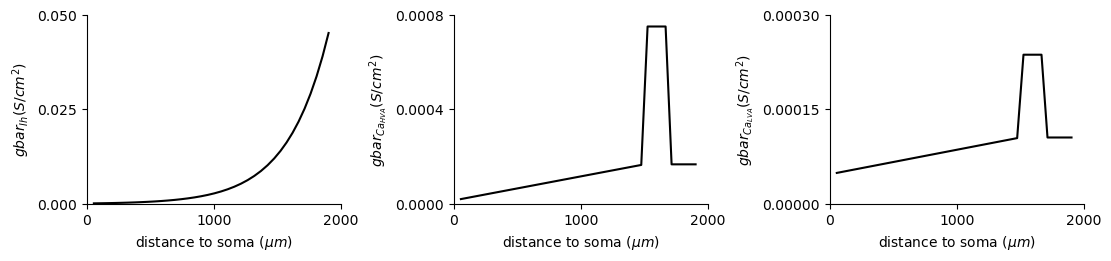

In [3]:
model = get_l5pyr()
apical_sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
distance_apical = []
gbar_Ih_apical = []
gbar_Ca_HVA_apical = []
gbar_Ca_LVA_apical = []

h.distance(sec=model._nrn_sections['soma'])
for section in apical_sections:
    for seg in model._nrn_sections[section]:
        distance_apical.append(h.distance(seg.x, sec=seg.sec))
        gbar_Ih_apical.append(seg.gbar_Ih_hay2011)
        gbar_Ca_HVA_apical.append(seg.gbar_Ca_HVA_hay2011)
        gbar_Ca_LVA_apical.append(seg.gbar_Ca_LVAst_hay2011)

fig, ax = plt.subplots(1, 3, figsize=(11, 2.5), constrained_layout=True)
ax[0].plot(distance_apical, gbar_Ih_apical, color='k')
ax[0].set_ylim([0.0, 0.05])
ax[0].set_yticks([0.0, 0.025, 0.05])
ax[0].set_ylabel(r'$gbar_{Ih} (S/cm^2)$')
ax[0].set_xlabel(r'distance to soma ($\mu m$)')

ax[1].plot(distance_apical, gbar_Ca_HVA_apical, color='k')
ax[1].set_ylabel(r'$gbar_{Ca_{HVA}} (S/cm^2)$')
ax[1].set_xlabel(r'distance to soma ($\mu m$)')
ax[1].set_ylim([0.0, 0.0008])
ax[1].set_yticks([0.0, 0.0008 / 2, 0.0008])

ax[2].plot(distance_apical, gbar_Ca_LVA_apical, color='k')
ax[2].set_ylabel(r'$gbar_{Ca_{LVA}} (S/cm^2)$')
ax[2].set_xlabel(r'distance to soma ($\mu m$)')
ax[2].set_ylim([0.0, 0.0003])
ax[2].set_yticks([0.0, 0.0003 / 2, 0.0003])

for a in ax:
    a.set_xlim([0, 2000])
    a.set_xticks([0, 1000, 2000])
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

fig.savefig(figpth / 'l5_conductances_apical.png', dpi=300)
fig.savefig(figpth / 'l5_conductances_apical.pdf', dpi=300)
fig.savefig(figpth / 'l5_conductances_apical.svg', dpi=300)
plt.show()

## Supp. Fig. 1c — conductances (basal) + back-propagating AP attenuation

Na/K `gbar` in the basal + oblique dendrites, and the amplitude of the
back-propagating action potential as a function of distance from the soma.

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.


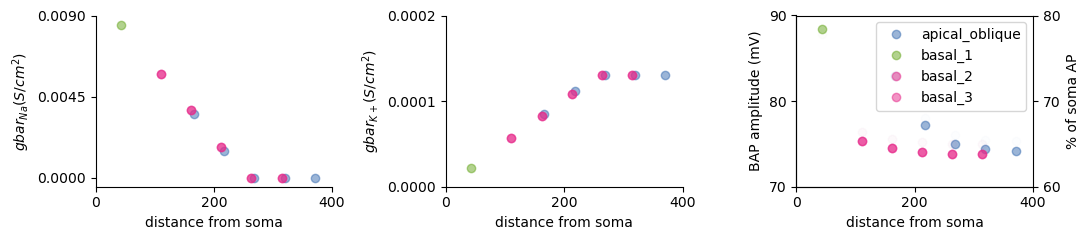

In [4]:
h.dt = 0.025  # explicit dt (chirp and action potential set their own)
cell_type = 'ET'
model = get_l5pyr()

l_stim = 150
section_names = ['apical_oblique', 'basal_1', 'basal_2', 'basal_3']
voltg = [None] * len(section_names)

stim = h.IClamp(model._nrn_sections['soma'](0.5))
stim.delay = 20
stim.dur = 5
stim.amp = 3

v_soma = h.Vector().record(model._nrn_sections['soma'](0.5)._ref_v)

h.distance(sec=model._nrn_sections['soma'])
for s, section in enumerate(section_names):
    voltg[s] = dict()
    for seg in model._nrn_sections[section]:
        voltg[s][seg.x] = h.Vector().record(seg._ref_v)

t = h.Vector().record(h._ref_t)
h.celsius = 37
h.finitialize()
h.continuerun(l_stim * ms)

v_soma = v_soma.as_numpy()

fig, ax = plt.subplots(1, 3, figsize=(11, 2.5))
ax12_tw = ax[2].twinx()
ax12_tw.set_ylabel('% of soma AP')
for s, section in enumerate(section_names):
    Nagbar = []
    Kbar = []
    amp = []
    amp_percent = []
    dist = []
    for seg in model._nrn_sections[section]:
        dist.append(h.distance(seg.x, sec=seg.sec))

        if cell_type == 'ET':
            Nagbar.append(seg.gbar_NaTs2_t_hay2011)
        elif cell_type == 'IT':
            Nagbar.append(seg.gbar_NaTs2_t_32d_hay2011)
        Kbar.append(seg.gbar_SKv3_1_hay2011)

    # get amplitude
    for segx in voltg[s].keys():
        vmax = np.max(voltg[s][segx].as_numpy())
        vmin = np.min(voltg[s][segx].as_numpy())
        amp.append(vmax - vmin)
        amp_percent.append((vmax - vmin) / (np.max(v_soma) - np.min(v_soma)) * 100)

    ax[0].plot(dist, Nagbar, 'o', color=col_basal[s], alpha=0.5)
    ax[0].set_xlabel('distance from soma')
    ax[0].set_ylabel(r'$gbar_{Na} (S/cm^2)$')
    ax[0].set_ylim([-0.0005, 0.009])
    ax[0].set_yticks([0, 0.0045, 0.009])

    ax[1].plot(dist, Kbar, 'o', color=col_basal[s], alpha=0.5)
    ax[1].set_xlabel('distance from soma')
    ax[1].set_ylabel(r'$gbar_{K+} (S/cm^2)$')
    ax[1].set_ylim([0, 0.0002])
    ax[1].set_yticks([0, 0.0001, 0.0002])
    ax[2].plot(dist, amp, 'o', color=col_basal[s], alpha=0.5, label=section)
    ax[2].set_xlabel('distance from soma')
    ax[2].set_ylabel('BAP amplitude (mV)')
    ax[2].set_ylim([70, 90])
    ax[2].set_yticks([70, 80, 90])
    ax12_tw.plot(dist, amp_percent, 'o', color=col_basal[s], alpha=0.01)
    ax12_tw.set_ylim([60, 80])
    ax12_tw.set_yticks([60, 70, 80])

    ax[2].legend()

    for a in ax:
        a.set_xlim([0, 400])
        a.set_xticks([0, 200, 400])

for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

fig.tight_layout()
fig.savefig(figpth / 'l5_conductances_basal_bAP.png', dpi=300)
fig.savefig(figpth / 'l5_conductances_basal_bAP.pdf', dpi=300)
fig.savefig(figpth / 'l5_conductances_basal_bAP.svg', dpi=300)
plt.show()

## Fig. 2b — in-vitro experiments (vs Kalmbach et al. 2021)

Resting potential, action potential, burst ISI, FI curve, sub-threshold
resonance (chirp), and the sag/rebound relationship. Each experiment is
rendered as a standalone figure and, via `plot_all_experiments`, assembled into
the original 3x3 gridspec layout (`l5cell_experiments`). The scalar measures
computed here (`rmp`, `ap_thresh`, `ap_peak`, `ap_hw`, `f_AHP`, `min_burst_isi`,
`max_fi`, `res_freq`, `cutoff3db_freq`, `rebound_slope`, `inp_res_max`,
`sag_ratio`) feed the comparison violins in Fig. 2c.

### Plotting functions (Fig. 2)

Each function draws one experiment's panel(s) into supplied axes, reading the
results stored by the corresponding experiment cell below. Reused for both the
standalone figures and the combined layout, so the two can't drift apart.

In [5]:
def _despine(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def plot_rmp(ax):
    ax.plot(rmp_t, rmp_v, color=cm_neurons[3], linewidth=2)
    ax.plot(rmp_t[-3], rmp_v[-3], 'o', color='k', markersize=7)
    ax.set_ylabel('membrane \n potential (mV)')
    ax.set_xlabel('time (ms)')
    ax.set_xlim([0, 105])
    ax.set_xticks([0, 50, 100])
    ax.set_ylim([-75, -65])
    ax.set_yticks([-75, -65])
    _despine(ax)


def plot_action_potential(ax):
    ax.plot(ap_t, ap_v, color=cm_neurons[3], linewidth=2)
    ax.plot(ap_t[np.argmax(ap_v)], ap_peak, 'o', color=marker_colors[0], markersize=7)
    ax.plot(ap_t[ap_thresh_idx], ap_thresh, 'o', color=marker_colors[1], markersize=7)
    ax.plot(ap_t[ap_elbow_p], ap_v[ap_elbow_p], 'o', color=marker_colors[3], markersize=7)
    ax.set_ylim([-80, 50])
    ax.set_yticks([-70, 0, 50])
    ax.set_xlim([0, 20])
    ax.set_xlabel('time (ms)')
    _despine(ax)


def plot_isi(ax):
    ax.plot(isi_t, isi_v, color=cm_neurons[3], linewidth=2)
    ax.set_xlim([0, 2000])
    ax.set_xticks(np.arange(0, 2001, 500))
    ax.set_ylim([-80, 50])
    ax.set_yticks([-70, 0, 50])
    ax.set_xlabel('time (ms)')
    _despine(ax)


def plot_fi(ax):
    ax.plot(fi_ampls, fi_F, color=cm_neurons[3], linewidth=2)
    ax.set_ylabel('firing rate (Hz)')
    ax.set_xlabel('current injection (nA)')
    ax.set_xlim([0, 2])
    ax.set_xticks(np.arange(0, 2.1, 0.5))
    ax.set_ylim([0, 20])
    ax.set_yticks(np.arange(0, 21, 10))
    _despine(ax)


def plot_chirp(ax_trace, ax_imp):
    ax_trace.plot(chirp_t, chirp_v, color=cm_neurons[3], linewidth=2)
    ax_trace.set_xlabel('time (ms)')
    ax_trace.set_ylabel('membrane \n potential (mV)')
    ax_trace.set_xlim([0, 20000])
    ax_trace.set_xticks(np.arange(0, 20001, 10000))
    ax_trace.set_ylim([-73.5, -69.5])
    ax_trace.set_yticks([-73.5, -69.5])
    _despine(ax_trace)

    ax_imp.plot(chirp_freq, chirp_zap, color=cm_neurons[3], linewidth=2)
    ax_imp.plot(res_freq, chirp_res_zap, 'o', color='k', markersize=7)
    ax_imp.plot(cutoff3db_freq, cutoff3db, 'o', color=marker_colors[0], markersize=7)
    ax_imp.set_xlabel('frequency (Hz)')
    ax_imp.set_ylabel('amplitude')
    ax_imp.set_xlim([0, 40])
    ax_imp.set_xticks(np.arange(0, 41, 10))
    ax_imp.set_ylim([0, 1.1])
    ax_imp.set_yticks([0, 1])
    _despine(ax_imp)


def plot_sag(ax_traces, ax_rebound):
    for v_row in sag_soma_v:
        ax_traces.plot(sag_t, v_row, color=cm_neurons[3])
    ax_traces.set_ylabel('membrane \n potential (mV)')
    ax_traces.set_xlabel('time (ms)')
    ax_traces.set_xlim([0, 1200])
    ax_traces.set_xticks(np.arange(0, 1201, 400))
    ax_traces.set_ylim([-80, -70])
    ax_traces.set_yticks([-80, -70])
    _despine(ax_traces)

    ax_rebound.plot(sag_steady_state, sag_peak_heights, color=cm_neurons[3])
    ax_rebound.set_xlabel('steady state (mV)')
    ax_rebound.set_ylabel('depolarization \n potential (mV)')
    ax_rebound.set_ylim([-72, -70])
    ax_rebound.set_yticks([-72, -70])
    ax_rebound.set_xlim([-78, -71])
    ax_rebound.set_xticks([-78, -71])
    _despine(ax_rebound)


def plot_all_experiments(fig=None):
    """Assemble every Fig. 2b experiment into the original 3x3 gridspec layout.

    Returns the figure and its axes. Requires that all experiment cells below
    have already run (it reads their stored results).
    """
    if fig is None:
        fig = plt.figure(figsize=(12, 8), constrained_layout=True)
    gs = gridspec.GridSpec(3, 3, figure=fig, width_ratios=[0.5, 0.5, 1])
    ax_0_0 = fig.add_subplot(gs[0, 0])
    ax_0_1 = fig.add_subplot(gs[0, 1])
    ax_0_2 = fig.add_subplot(gs[0, 2])
    ax_1_0 = fig.add_subplot(gs[1, 0])
    ax_1_1 = fig.add_subplot(gs[1, 1])
    ax_1_2 = fig.add_subplot(gs[1, 2])
    ax_2_0 = fig.add_subplot(gs[2, 0:2])
    ax_2_1 = fig.add_subplot(gs[2, 2])

    plot_rmp(ax_0_0)
    plot_action_potential(ax_0_1)
    plot_isi(ax_0_2)
    plot_chirp(ax_1_0, ax_1_1)
    plot_fi(ax_1_2)
    plot_sag(ax_2_0, ax_2_1)
    return fig, [ax_0_0, ax_0_1, ax_0_2, ax_1_0, ax_1_1, ax_1_2, ax_2_0, ax_2_1]

### Resting membrane potential

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
{'soma': np.float64(-71.67156267475032), 'basal_1': np.float64(-71.75783468429482), 'basal_2': np.float64(-71.88609756475624), 'basal_3': np.float64(-71.88609756475624), 'apical_oblique': np.float64(-71.6428617972303), 'apical_trunk': np.float64(-71.61285480983923), 'apical_1': np.float64(-70.48250876630362), 'apical_2': np.float64(-66.22649618666968), 'apical_tuft': np.float64(-61.48590102744457)}


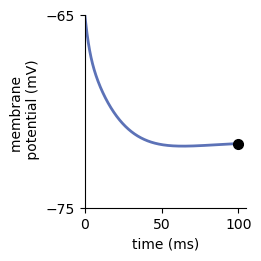

In [6]:
h.dt = 0.025  # explicit dt (chirp and action potential set their own)
l5pyr = get_l5pyr(v_init={'soma': -65, 'basal_1': -65, 'basal_2': -65, 'basal_3': -65,
                          'apical_oblique': -65, 'apical_trunk': -65, 'apical_1': -65,
                          'apical_2': -65, 'apical_tuft': -65})

t = h.Vector().record(h._ref_t)
section_names = ['soma', 'basal_1', 'basal_2', 'basal_3', 'apical_oblique', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
v_s = []
for s, section in enumerate(section_names):
    v_s.append(h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_v))

h.celsius = 37
h.finitialize()
h.continuerun(100 * ms)

v_init = {}
for s, section in enumerate(section_names):
    if section == 'soma':
        soma_voltg = v_s[s].as_numpy()
    v = v_s[s].as_numpy()
    v_init[section] = v[-1]

print(v_init, flush=True)
rmp = soma_voltg[-3]

# store results for plotting
rmp_t = t.as_numpy().copy()
rmp_v = soma_voltg.copy()

fig, ax = plt.subplots(figsize=(2.5, 2.5), constrained_layout=True)
plot_rmp(ax)
plt.show()

### Action potential

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.


/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_77214/1712029904.py:35: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  start = int(ap)


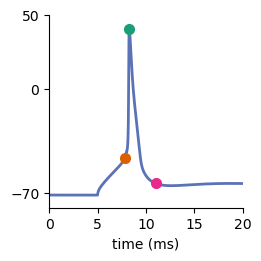

In [7]:
l5pyr = get_l5pyr()
stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 3
stim.amp = 3
clamp_current = h.Vector().record(stim._ref_i)

t = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
iclamp = h.Vector().record(stim._ref_i)

h.celsius = 37
h.dt = .01
h.finitialize()
h.continuerun(100 * ms)

ap, properties = find_peaks(v_soma.as_numpy(), height=0, width=0)

v_grad = np.gradient(v_soma)
smooth_v = signal.savgol_filter(np.diff(v_soma.as_numpy()), 101, 3)

ap_thresh_idx = np.where(smooth_v / np.diff(t.as_numpy()) > 20)[0][0] + 1
ap_thresh = v_soma[ap_thresh_idx]

if len(ap) > 0:
    ap_peak = properties['peak_heights'][0]
else:
    ap_peak = v_soma[-1]

v2 = np.gradient(np.gradient(v_soma.as_numpy()))
ahp, props_v2 = find_peaks(-v2, width=1)
ap_hw = properties['widths'][0] * h.dt
v2 = np.gradient(np.gradient(smooth_v))

start = int(ap)
stop = int(np.where(t.as_numpy() > 11)[0][0])
elbow_p = int(np.argmin(v_soma.as_numpy()[start:stop]) + start)
f_AHP = v_soma.as_numpy()[elbow_p] - ap_thresh

# store results for plotting
ap_t = t.as_numpy().copy()
ap_v = v_soma.as_numpy().copy()
ap_elbow_p = elbow_p

fig, ax = plt.subplots(figsize=(2.5, 2.5), constrained_layout=True)
plot_action_potential(ax)
plt.show()

### Burst ISI

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.


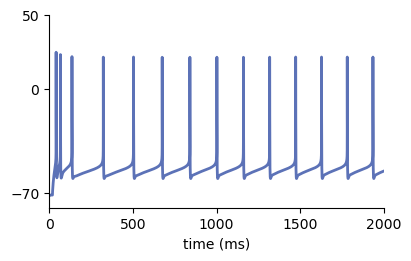

In [8]:
h.dt = 0.025  # explicit dt (chirp and action potential set their own)
l5pyr = get_l5pyr()
stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 20
stim.dur = 2000
stim.amp = .8
iclamp = h.Vector().record(stim._ref_i)
t = h.Vector().record(h._ref_t)
soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
h.celsius = 37
h.finitialize()
h.continuerun(2000 * ms)

idx = np.argmin(np.abs(t.as_numpy() - 100))
spk, prop = signal.find_peaks(soma_voltg.as_numpy()[:idx], height=0)
min_burst_isi = np.mean(np.diff(t.as_numpy()[spk]))

# store results for plotting
isi_t = t.as_numpy().copy()
isi_v = soma_voltg.as_numpy().copy()

fig, ax = plt.subplots(figsize=(4, 2.5), constrained_layout=True)
plot_isi(ax)
plt.show()

### FI curve

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_bro

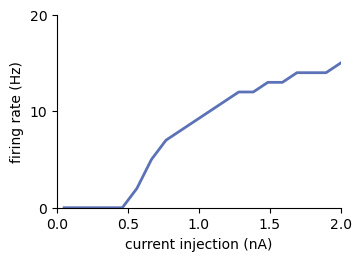

In [9]:
h.dt = 0.025  # explicit dt (chirp and action potential set their own)
del l5pyr
h('forall delete_section()')
ampls = np.linspace(.05, 2, 20)

F = np.zeros_like(ampls)
for i, amp in enumerate(ampls):
    l5pyr = get_l5pyr()
    stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
    stim.delay = 1
    stim.dur = 1000
    stim.amp = amp
    t = h.Vector().record(h._ref_t)
    soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
    h.celsius = 37
    h.finitialize()
    h.continuerun(1001 * ms)
    soma_voltg = soma_voltg.as_numpy()
    F[i] = len(signal.find_peaks(soma_voltg, height=0)[0])

FI_slope = np.diff(np.array(F)) / np.diff(ampls)[0]
pA = 0.001
max_fi = max(FI_slope) * pA

# store results for plotting
fi_ampls = ampls.copy()
fi_F = F.copy()

fig, ax = plt.subplots(figsize=(3.5, 2.5), constrained_layout=True)
plot_fi(ax)
plt.show()

### Sub-threshold resonance (chirp)

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.


/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_77214/1739638003.py:34: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  maxf = int(np.where(freq == 40)[0])


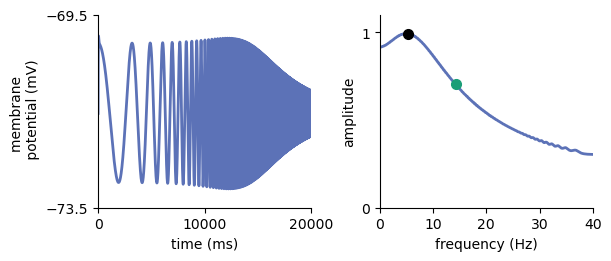

In [10]:
l5pyr = get_l5pyr()
stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 0
h.tstop = 20_100
stim.dur = h.tstop
h.dt = 0.1

t_chirp = np.arange(0, stim.dur, h.dt)
f0 = 0.2
f1 = 40
A = .05
chirp_signal = A * chirp(t_chirp / 1000, f0, 20, f1, method='log')

stim.amp = 0
stim_vec = h.Vector(chirp_signal)
t = np.arange(0, stim.dur, h.dt)
time_vec = h.Vector(t)
stim_vec.play(stim._ref_amp, time_vec, 1)

v_rec = h.Vector()
v_rec.record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
t_rec = h.Vector().record(h._ref_t)
h.finitialize()
h.continuerun(h.tstop)

hann_win = windows.hann(len(chirp_signal), len(chirp_signal) * 1.)
N = len(v_rec) - 1001
T = h.dt / 1000
freq = fftfreq(N, T)[:N // 2]
lowf = np.argmin(np.abs(freq - 0.2))

fft_membr = fft(v_rec.as_numpy()[1:])
fft_chirp = fft(chirp_signal)
maxf = int(np.where(freq == 40)[0])

freq = freq[lowf:maxf]
Z = fft_membr[lowf:maxf] / fft_chirp[lowf:maxf]
zap = np.abs(Z[:N // 2])
norm_zap = zap / zap.max()

res_freq = freq[np.argmax(zap)]
res_freq_idx = np.argmin(np.abs(freq - res_freq))
cutoff3db = np.sqrt(0.5 * norm_zap.max())
cutoff3db_idx = np.argmin(np.abs(norm_zap - cutoff3db))
cutoff3db_freq = freq[cutoff3db_idx]
zap_smooth = savgol_filter(norm_zap, window_length=10, polyorder=1)

# store results for plotting
chirp_t = t_rec.as_numpy().copy()
chirp_v = v_rec.as_numpy().copy()
chirp_freq = freq.copy()
chirp_zap = zap_smooth.copy()
chirp_res_zap = zap_smooth[np.argmax(norm_zap)]

fig, ax = plt.subplots(1, 2, figsize=(6, 2.5), constrained_layout=True)
plot_chirp(ax[0], ax[1])
plt.show()

### Sag ratio and rebound

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.


/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_77214/1625167578.py:30: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  peak_heights[i] = pk[1]['peak_heights']


Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_bro

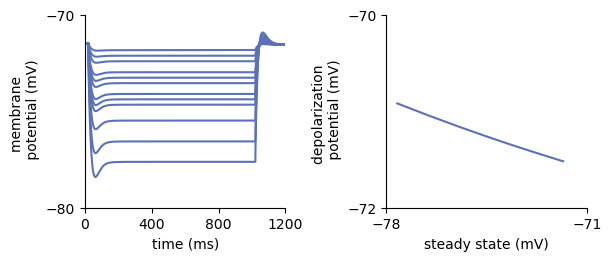

In [11]:
h.dt = 0.025  # explicit dt (chirp and action potential set their own)
sag_stim_amp = l5_allen['sag_stim_amp'].dropna()
sag_stim_amp = np.unique(np.concatenate(sag_stim_amp.values))

soma_v = np.zeros((len(sag_stim_amp), int(1 / h.dt * 1200 + 1)))
peak_heights = np.zeros_like(sag_stim_amp)
steady_state = np.zeros_like(sag_stim_amp)
min_membr_pot = np.zeros_like(sag_stim_amp)
for i, amp in enumerate(sag_stim_amp):
    l5pyr = get_l5pyr()
    stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
    stim.delay = 20
    stim.dur = 1000
    stim.amp = amp
    clamp_current = h.Vector().record(stim._ref_i)
    t = h.Vector().record(h._ref_t)
    soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
    h.celsius = 37
    h.finitialize()
    h.continuerun(1200 * ms)

    steady_idx = np.argmin(np.abs(t - 1000))
    soma_v[i] = soma_voltg.as_numpy()
    pk = find_peaks(soma_v[i][steady_idx:], height=[-90, 50])
    if len(pk[0]) > 1:
        peak_heights[i] = pk[1]['peak_heights'][0]
    elif len(pk[0]) == 0:
        peak_heights[i] = np.nan
    else:
        peak_heights[i] = pk[1]['peak_heights']
    min_membr_pot[i] = np.min(soma_v[i])
    steady_state[i] = soma_v[i][steady_idx]

rebound_slope = np.polyfit(steady_state, peak_heights, 1)[0]
inp_res_max = np.polyfit(sag_stim_amp, min_membr_pot, 1)[0]
inp_res_steady = np.polyfit(sag_stim_amp, steady_state, 1)[0]
sag_ratio = inp_res_max / inp_res_steady

# store results for plotting
sag_t = t.as_numpy().copy()
sag_soma_v = soma_v
sag_steady_state = steady_state.copy()
sag_peak_heights = peak_heights.copy()

fig, ax = plt.subplots(1, 2, figsize=(6, 2.5), constrained_layout=True)
plot_sag(ax[0], ax[1])
plt.show()

### Combined figure (original layout)

Reassembles all Fig. 2b panels into the original 3x3 gridspec.

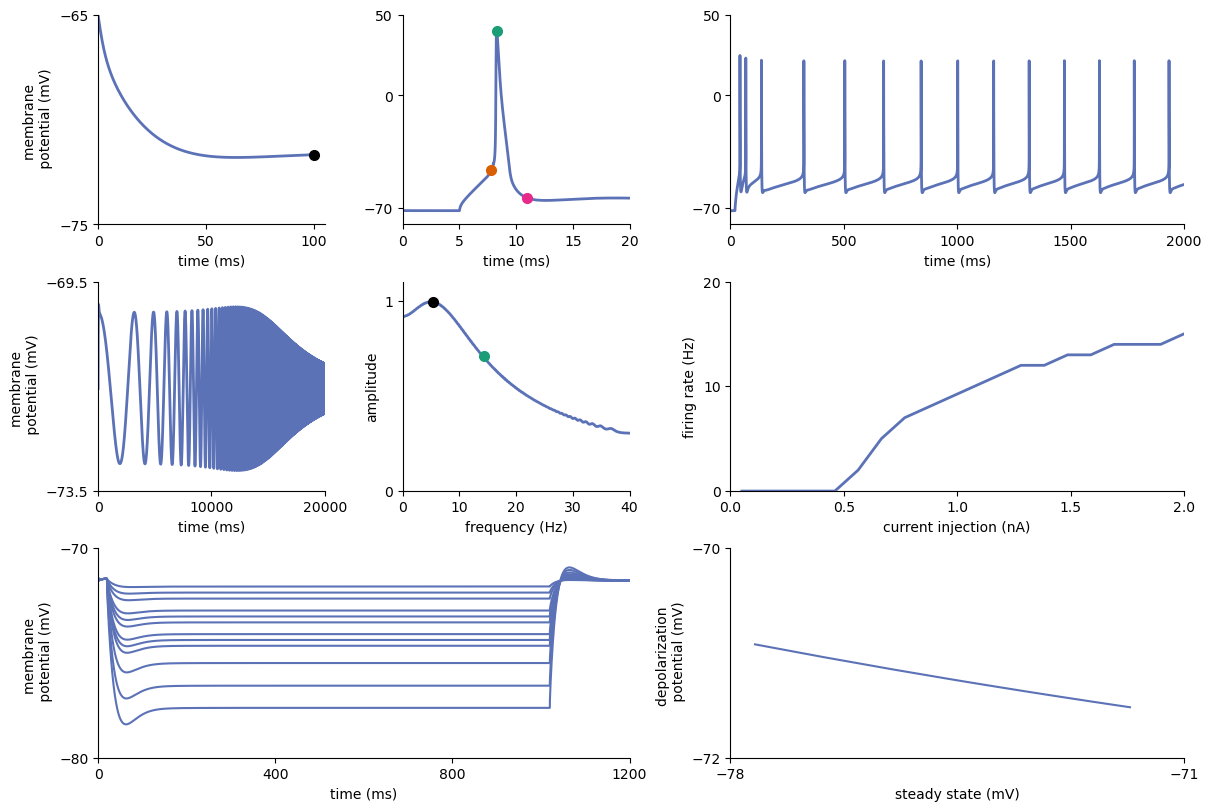

In [12]:
fig, axes = plot_all_experiments()
plt.show()
fig.savefig(figpth / 'l5cell_experiments.pdf', dpi=300)
fig.savefig(figpth / 'l5cell_experiments.png', dpi=300)
fig.savefig(figpth / 'l5cell_experiments.svg', dpi=300)

## Fig. 2c — comparison to Kalmbach et al. 2021 (violins)

Model measures (computed in Fig. 2b) overlaid on the Kalmbach ET-cell
distributions.

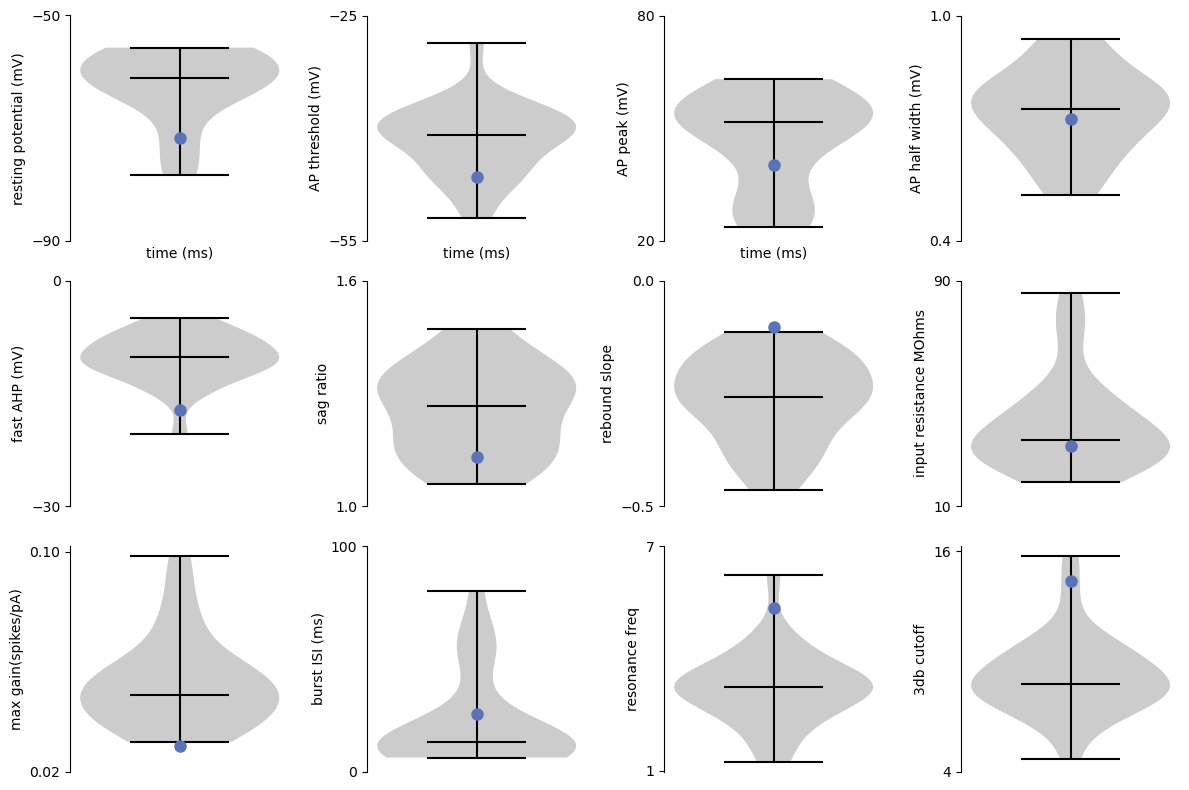

In [13]:
fig, ax = plt.subplots(3, 4, figsize=(12, 8))

viol = [None] * 12
ax = ax.ravel()
viol[0] = ax[0].violinplot(l5df['RMP'], vert=True, showmeans=False, showmedians=True)
ax[0].set_yticks(np.arange(-80, -40, 10))
ax[0].plot(1, rmp, 'o', color=cm_neurons[3], markersize=8)
ax[0].set_xlabel('time (ms)')
ax[0].set_ylim([-90, -50])
ax[0].set_yticks([-90, -50])
ax[0].set_ylabel('resting potential (mV)')

viol[1] = ax[1].violinplot(l5df['AP_threshold'], vert=True, showmeans=False, showmedians=True)
ax[1].plot(1, ap_thresh, 'o', color=cm_neurons[3], markersize=8)
ax[1].set_xlabel('time (ms)')
ax[1].set_ylim([-55, -25])
ax[1].set_yticks([-55, -25])
ax[1].set_ylabel('AP threshold (mV)')

viol[2] = ax[2].violinplot(l5df['AP_peak'], vert=True, showmeans=False, showmedians=True)
ax[2].plot(1, ap_peak, 'o', color=cm_neurons[3], markersize=8)
ax[2].set_yticks([20, 80])
ax[2].set_ylabel('AP peak (mV)')
ax[2].set_xlabel('time (ms)')

viol[3] = ax[3].violinplot(l5df['AP_HW'], vert=True, showmeans=False, showmedians=True)
ax[3].plot(1, ap_hw, 'o', color=cm_neurons[3], markersize=8)
ax[3].set_ylabel('AP half width (mV)')
ax[3].set_yticks([0.4, 1.0])

viol[4] = ax[4].violinplot(l5df['f_AHP'], vert=True, showmeans=False, showmedians=True)
ax[4].plot(1, f_AHP, 'o', color=cm_neurons[3], markersize=8)
ax[4].set_ylabel('fast AHP (mV)')
ax[4].set_yticks([-30, 0])

viol[5] = ax[5].violinplot(l5df['Sag_ratio'], vert=True, showmeans=False, showmedians=True)
ax[5].set_yticks([1, 1.6])
ax[5].set_ylim([1, 1.6])
ax[5].plot(1, sag_ratio, 'o', color=cm_neurons[3], markersize=8)
ax[5].set_ylabel('sag ratio')

viol[6] = ax[6].violinplot(l5df['Rebound'], vert=True, showmeans=False, showmedians=True)
ax[6].plot(1, rebound_slope, 'o', color=cm_neurons[3], markersize=8)
ax[6].set_yticks([-0.5, 0])
ax[6].set_ylabel('rebound slope')

viol[7] = ax[7].violinplot(l5df['SSRn'], vert=True, showmeans=False, showmedians=True)
ax[7].plot(1, inp_res_max, 'o', color=cm_neurons[3], markersize=8)
ax[7].set_ylabel('input resistance MOhms')
ax[7].set_yticks([10, 90])

viol[8] = ax[8].violinplot(l5df['FI_slope_max'], vert=True, showmeans=False, showmedians=True)
ax[8].plot(1, max_fi, 'o', color=cm_neurons[3], markersize=8)
ax[8].set_ylabel('max gain(spikes/pA)')
ax[8].set_yticks([0.02, 0.1])

viol[9] = ax[9].violinplot(l5df['min_burst_ISI_5'][~np.isnan(l5df['min_burst_ISI_5'])], vert=True, showmeans=False, showmedians=True)
ax[9].plot(1, min_burst_isi, 'o', color=cm_neurons[3], markersize=8)
ax[9].set_ylabel('burst ISI (ms)')
ax[9].set_yticks([0, 100])

viol[10] = ax[10].violinplot(l5df['Fr'], vert=True, showmeans=False, showmedians=True)
ax[10].plot(1, res_freq, 'o', color=cm_neurons[3], markersize=8)
ax[10].set_yticks([1, 7])
ax[10].set_ylabel('resonance freq')

viol[11] = ax[11].violinplot(l5df['Cutoff'].values[np.isnan(l5df['Cutoff'].values) == False], vert=True, showmeans=False, showmedians=True)
ax[11].plot(1, cutoff3db_freq, 'o', color=cm_neurons[3], markersize=8)
ax[11].set_ylabel('3db cutoff')
ax[11].set_yticks([4, 16])

for v in viol:
    for pc in v['bodies']:
        pc.set_facecolor('black')
        pc.set_alpha(0.2)
    v['cbars'].set_color('black')
    v['cmaxes'].set_color('black')
    v['cmins'].set_color('black')
    v['cmedians'].set_color('black')

for a in ax:
    a.set_xticks([])
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.spines['bottom'].set_visible(False)

fig.tight_layout()
plt.show()
fig.savefig(figpth / 'l5cell_vs_kalmbach2021.pdf')
fig.savefig(figpth / 'l5cell_vs_kalmbach2021.svg')
fig.savefig(figpth / 'l5cell_vs_kalmbach2021.png')

## Fig. 3b — calcium spikes triggered by critical-frequency input

Somatic pulse trains at increasing frequency; the apical tuft (blue) fires a
calcium spike once the critical frequency is reached.

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.


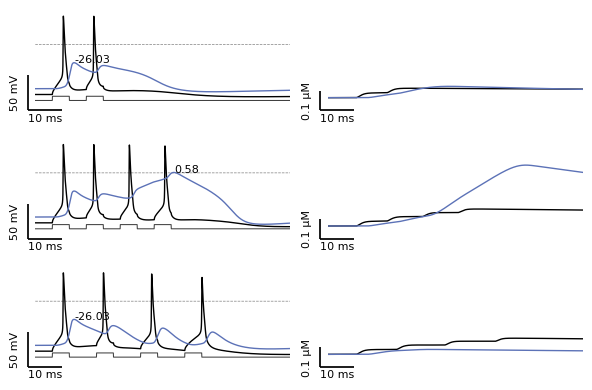

In [14]:
fig, ax = plt.subplots(3, 2, figsize=(6, 4))
h('forall delete_section()')
nums_pulse = [2, 4, 4]
time_diff = [10, 10, 13]
l_stim = 500
h.dt = 0.025  # NEURON's h.dt is global; the Fig. 2b chirp left it at 0.1 (too coarse for Ca spikes)

for n, num_pulse in enumerate(nums_pulse):
    l5pyr = get_l5pyr()

    stim = [None] * num_pulse
    t = h.Vector().record(h._ref_t)
    for i in range(num_pulse):
        stim[i] = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
        stim[i].delay = 20 + (time_diff[n] * i)
        stim[i].dur = 5
        stim[i].amp = 3

    soma_v = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
    soma_ca = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_cai)
    tuft_v = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.1)._ref_v)
    tuft_ca = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.1)._ref_cai)

    h.celsius = 37
    h.finitialize()
    h.continuerun(l_stim * ms)

    clamp_current = np.zeros_like(t.as_numpy())
    for i in range(num_pulse):
        clamp_current[(t.as_numpy() > stim[i].delay) & (t.as_numpy() < stim[i].delay + stim[i].dur)] = stim[i].amp

    ax[n, 0].plot(t.as_numpy(), np.zeros_like(t.as_numpy()), color='black', alpha=0.5, linewidth=0.5, linestyle='--')
    ax[n, 0].plot(t, soma_v, color='k', linewidth=1)
    ax[n, 0].plot(t.as_numpy(), clamp_current * 2 - 80, color='black', alpha=0.75, linewidth=0.75)
    ax[n, 1].plot(t, soma_ca, color='k', linewidth=1)

    v_max = np.max(tuft_v.as_numpy())
    t_max = np.argmax(tuft_v.as_numpy())
    ax[n, 0].text(t[t_max], v_max, f'{v_max:.2f}', fontsize=8)
    ax[n, 0].plot(t, tuft_v, color=cm_neurons[3], alpha=1, linewidth=1)
    ax[n, 1].plot(t, tuft_ca, label=f'{num_pulse} pulses, {time_diff[n]} ms apart', color=cm_neurons[3], alpha=1, linewidth=1)

    ax[n, 0].set_xlim([15, 90])
    ax[n, 1].set_xlim([15, 90])
    ax[n, 0].set_ylim([-90, 50])
    ax[n, 1].set_ylim([0, 0.0005])

    # scale bars: x = 10 ms; y = 50 mV (voltage) / 0.1 uM ([Ca])
    add_scalebar(ax[n, 0], x_len=10, y_len=50, x_label='10 ms', y_label='50 mV')
    add_scalebar(ax[n, 1], x_len=10, y_len=0.0001, x_label='10 ms', y_label='0.1 µM')

fig.tight_layout()
fig.savefig(figpth / 'l5_caspike_critical_frequency.png', dpi=300)
fig.savefig(figpth / 'l5_caspike_critical_frequency.pdf', dpi=300)
fig.savefig(figpth / 'l5_caspike_critical_frequency.svg', dpi=300)
plt.show()

## Fig. 3c — calcium-spike measures

Apical membrane-potential integral as a function of input frequency, and the
calcium-spike threshold as a function of distance from the soma.

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_bro

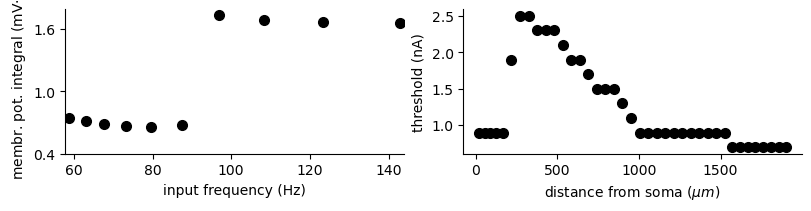

In [15]:
h.dt = 0.025  # explicit dt (chirp and action potential set their own)
fig, ax = plt.subplots(1, 2, figsize=(8, 2), constrained_layout=True)

# depolarization integral
time_diff = np.linspace(17, 7, 10)
freqs = np.zeros_like(time_diff)
apcl_integr = np.zeros_like(time_diff)
for n, td in enumerate(time_diff):
    l5pyr = get_l5pyr()

    t = h.Vector().record(h._ref_t)
    num_pulse = 4
    stim = [None] * 4
    for i in range(num_pulse):
        stim[i] = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
        stim[i].delay = 20 + (td * i)
        stim[i].dur = 5
        stim[i].amp = 3

    v_apcl = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.5)._ref_v)
    h.celsius = 37
    h.finitialize()
    h.continuerun(1020 * ms)

    freqs[n] = 1000 / td
    v_apcl = v_apcl.as_numpy()
    pk = find_peaks(v_apcl, prominence=15)
    apcl_integr[n] = np.sum(v_apcl - v_apcl[pk[1]['left_bases'][0]]) * h.dt * 0.001

    del l5pyr

ax[0].plot(freqs, apcl_integr, 'o', color='black', markersize=7)
ax[0].set_xlim([np.min(freqs) - 1, np.max(freqs) + 1])
#ax[0].set_ylim([0.4, 1.6])
ax[0].set_yticks([0.4, 1.0, 1.6])
ax[0].set_ylabel(r'membr. pot. integral (mV$\cdot$s)')
ax[0].set_xlabel('input frequency (Hz)')

# input threshold as a function of distance
section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
l5pyr = get_l5pyr()
threshold = []
for s, section in enumerate(section_names):
    for i, seg in enumerate(l5pyr._nrn_sections[section]):
        tuft_mp = -70  # initialize to a value below threshold
        amp = 0.1      # starting stimulation amplitude

        while tuft_mp < 0:  # has MP reached critical threshold?
            del l5pyr
            l5pyr = get_l5pyr()

            stim = h.IClamp(l5pyr._nrn_sections[section](seg.x))
            stim.delay = 20
            stim.dur = 100
            stim.amp = amp

            v = h.Vector().record(l5pyr._nrn_sections[section](seg.x)._ref_v)
            t = h.Vector().record(h._ref_t)

            h.celsius = 37
            h.finitialize()
            h.continuerun(100 * ms)

            tuft_mp = np.max(v.as_numpy())
            amp += 0.2

        threshold.append(amp)

# distance from soma (separate loop: l5pyr is repeatedly deleted above)
distance = []
h.distance(sec=l5pyr._nrn_sections['soma'])
for section in section_names:
    for i, seg in enumerate(l5pyr._nrn_sections[section]):
        distance.append(h.distance(seg.x, sec=seg.sec))

ax[1].plot(distance, threshold, 'o', color='k', markersize=7)
ax[1].set_ylabel('threshold (nA)')
ax[1].set_xlabel(r'distance from soma ($\mu m$)')

for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

fig.savefig(figpth / 'l5_ca_spike_measures.png', dpi=300)
fig.savefig(figpth / 'l5_ca_spike_measures.pdf', dpi=300)
fig.savefig(figpth / 'l5_ca_spike_measures.svg', dpi=300)
plt.show()

## Fig. 3d — calcium spikes triggered by coincidence detection

Somatic (black) and apical-tuft (red) inputs delivered alone and coincidentally;
coincident input evokes a calcium spike in the tuft (blue).

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.


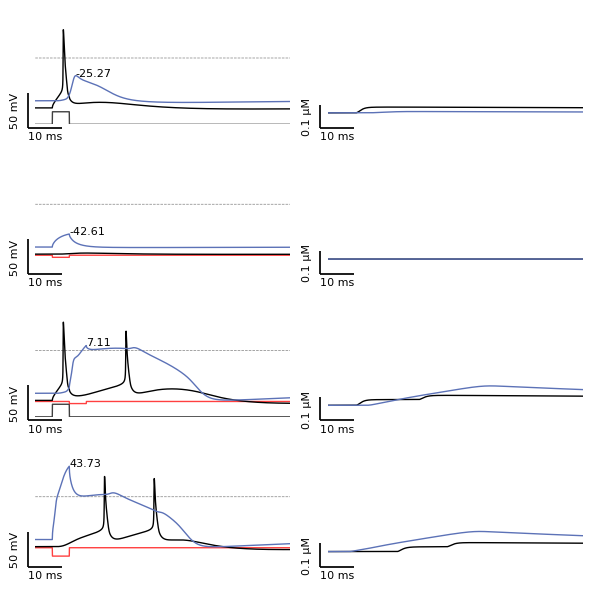

In [16]:
h.dt = 0.025  # explicit dt (chirp and action potential set their own)
fig, ax = plt.subplots(4, 2, figsize=(6, 6))

nums_pulse = [1, 1, 2, 1]
pulse_sect = [['soma'], ['apical_tuft'], ['soma', 'apical_tuft'], ['apical_tuft']]
ampl = [[3], [0.5], [3, 0.5], [2]]
time_diff = [[0], [0], [0, 5], [0]]
l_stim = 150

for n, num_pulse in enumerate(nums_pulse):
    l5pyr = get_l5pyr()

    stim = [None] * num_pulse
    t = h.Vector().record(h._ref_t)
    for i in range(num_pulse):
        stim[i] = h.IClamp(l5pyr._nrn_sections[pulse_sect[n][i]](0.5))
        stim[i].delay = 20 + (time_diff[n][i])
        stim[i].dur = 5
        stim[i].amp = ampl[n][i]

    soma_v = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
    soma_ca = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_cai)
    tuft_v = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.5)._ref_v)
    tuft_ca = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.5)._ref_cai)

    h.celsius = 37
    h.finitialize()
    h.continuerun(l_stim * ms)

    clamp_current = np.zeros((num_pulse, len(t.as_numpy())))
    for i in range(num_pulse):
        clamp_current[i][(t.as_numpy() > stim[i].delay) & (t.as_numpy() < stim[i].delay + stim[i].dur)] = stim[i].amp * 3

    for i in range(num_pulse):
        if pulse_sect[n][i] == 'soma':
            col = 'black'
            c = clamp_current[i] * 2 - 95
        else:
            col = 'red'
            c = -clamp_current[i] * 2 - 73
        ax[n, 0].plot(t.as_numpy(), c, color=col, alpha=0.75, linewidth=1)

    ax[n, 0].plot(t.as_numpy(), np.zeros_like(t.as_numpy()), color='black', alpha=0.5, linewidth=0.5, linestyle='--')
    ax[n, 0].plot(t, soma_v, color='k', linewidth=1)

    v_max = np.max(tuft_v.as_numpy())
    t_max = np.argmax(tuft_v.as_numpy())
    ax[n, 0].text(t[t_max], v_max, f'{v_max:.2f}', fontsize=8)
    ax[n, 0].plot(t, tuft_v, color=cm_neurons[3], alpha=1, linewidth=1)

    ax[n, 1].plot(t, soma_ca, color='k', linewidth=1)
    ax[n, 1].plot(t, tuft_ca, color=cm_neurons[3], alpha=1, linewidth=1)

    ax[n, 0].set_xlim([15, 90])
    ax[n, 1].set_xlim([15, 90])
    ax[n, 0].set_ylim(-95, 70)
    ax[n, 1].set_ylim([0, 0.0005])

    # scale bars: x = 10 ms; y = 50 mV (voltage) / 0.1 uM ([Ca])
    add_scalebar(ax[n, 0], x_len=10, y_len=50, x_label='10 ms', y_label='50 mV')
    add_scalebar(ax[n, 1], x_len=10, y_len=0.0001, x_label='10 ms', y_label='0.1 µM')

fig.tight_layout()
fig.savefig(figpth / 'l5_caspike_coincidence.png', dpi=300)
fig.savefig(figpth / 'l5_caspike_coincidence.pdf', dpi=300)
fig.savefig(figpth / 'l5_caspike_coincidence.svg', dpi=300)
plt.show()

## Signal attenuation — helper

Adapted from the L2/3 notebook for the L5 morphology (extra `apical_2` section).
Uses `attenuation_from_section` from `pyramidal_sim_utils`.

In [17]:
def plot_attenuation(model, ref_sect, section_names, use_epsp, cols_dist):

    fig, ax = plt.subplots(1, 5, figsize=(17, 2.5), constrained_layout=True)

    # hyperpolarization attenuation
    hyperpol_atten, elec_sep, _, ax[0] = attenuation_from_section(model=model, ref_sect=ref_sect, section_names=section_names, amp=-2, stim_dur=1000, ax=ax[0], cols_dist=cols_dist, epsp=False)
    popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(hyperpol_atten), p0=[100, hyperpol_atten[0]])
    lambda_hyperpol = popt[0]

    ax[1].plot(elec_sep, hyperpol_atten, 'o', color='w', markeredgecolor='k', markersize=7)
    ax[1].set_xlim(np.floor(elec_sep[0]), np.round(elec_sep[-1] + 100, -2))
    ax[1].set_xticks(np.linspace(0, np.round(elec_sep[-1] + 100, -2), 3))
    ax[1].set_xlabel(rf'distance from {ref_sect} ($\mu m$)')
    ax[1].set_ylabel('attenuation (%)')
    ax[1].set_ylim(0, 101)
    ax[1].plot(elec_sep, exp_decay(np.array(elec_sep), *popt), color='k')
    ax[1].text(200, 70, f'{lambda_hyperpol:.2f}')

    # spike attenuation
    model = get_l5pyr()

    spike_amp, _, upstroke, ax[2] = attenuation_from_section(model=model, ref_sect=ref_sect, section_names=section_names, amp=2, stim_dur=5, ax=ax[2], cols_dist=cols_dist, epsp=use_epsp)

    ax[3].plot(elec_sep, spike_amp, 'o', color='w', markeredgecolor='k', markersize=7)
    ax[3].set_xlim(np.floor(elec_sep[0]), np.round(elec_sep[-1] + 100, -2))
    ax[3].set_xticks(np.linspace(0, np.round(elec_sep[-1] + 100, -2), 3))
    popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(spike_amp), p0=[100, spike_amp[0]])
    lambda_spike_amp = popt[0]
    ax[3].plot(elec_sep, exp_decay(np.array(elec_sep), *popt), color='k')
    ax[3].text(100, spike_amp.max(), f'{lambda_spike_amp:.2f}')

    ax[3].set_xlabel(rf'distance from {ref_sect} ($\mu m$)')
    ax[3].set_ylabel('attenuation (%)')

    ax[2].set_xlim([0, 60])
    ax[3].set_yticks(np.arange(0, 101, 25))

    ax[4].plot(elec_sep, upstroke, 'o', color='w', markeredgecolor='k', markersize=7)
    ax[4].set_xlim(np.floor(elec_sep[0]), np.round(elec_sep[-1] + 100, -2))
    ax[4].set_xticks(np.linspace(0, np.round(elec_sep[-1] + 100, -2), 3))
    popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(upstroke), p0=[100, upstroke[0]])
    ax[4].plot(elec_sep, exp_decay(np.array(elec_sep), *popt), color='k')
    lambda_upstroke = popt[0]
    ax[4].set_ylabel('bAP upstroke (mV/ms)')
    ax[4].text(100, upstroke.max(), f'{lambda_upstroke:.2f}')

    for a in ax:
        a.spines['top'].set_visible(False)
        a.spines['right'].set_visible(False)

    return fig

## Supp. Fig. 2a — attenuation from soma (no EPSP)

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
ref section: soma, recording from section: apical_trunk
ref section: soma, recording from section: apical_1
ref section: soma, recording from section: apical_2
ref section: soma, recording from section: apical_tuft
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
ref section: soma, recording from section: apical_trunk
ref section: soma, recording from section: apical_1
ref section: soma, recording from section: apical_2
ref section: soma, recording from section: apical_tuft


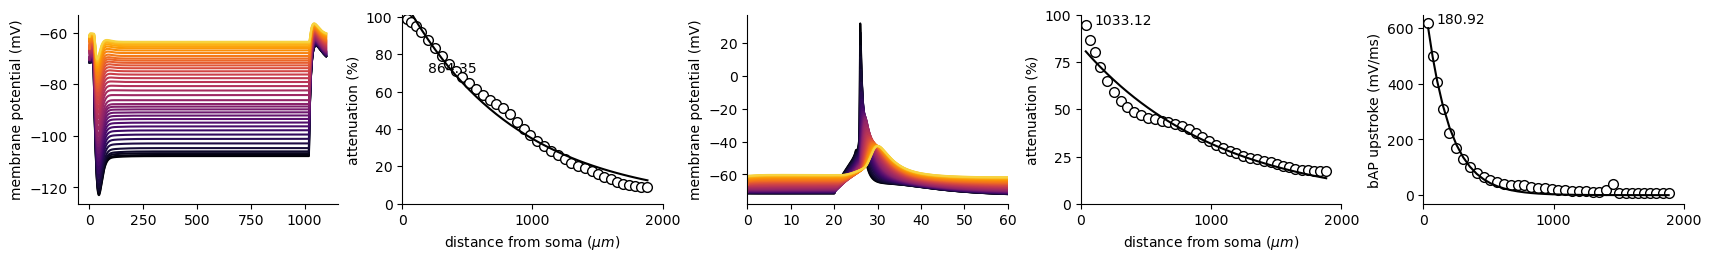

In [18]:
h.dt = 0.025  # explicit dt (chirp and action potential set their own)
model = get_l5pyr()
section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
ref_sect = 'soma'

fig = plot_attenuation(model=model, section_names=section_names, ref_sect=ref_sect, use_epsp=False, cols_dist=cols_dist)
fig.savefig(figpth / 'l5_attenuation_soma_dend.png', dpi=300)
fig.savefig(figpth / 'l5_attenuation_soma_dend.pdf', dpi=300)
plt.show()

## Supp. Fig. 2b — attenuation from tuft (EPSP input)

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
ref section: apical_tuft, recording from section: apical_tuft
ref section: apical_tuft, recording from section: apical_2
ref section: apical_tuft, recording from section: apical_1
ref section: apical_tuft, recording from section: apical_trunk
ref section: apical_tuft, recording from section: soma
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
ref section: apical_tuft, recording from section: apical_tuft
ref section: apical_tuft, recording from section: apical_2
ref section: apical_tuft, recording from section: apical_1
ref section: apical_tuft, recording from section: apical_trunk
ref section: apical_tuft, recording from section: soma


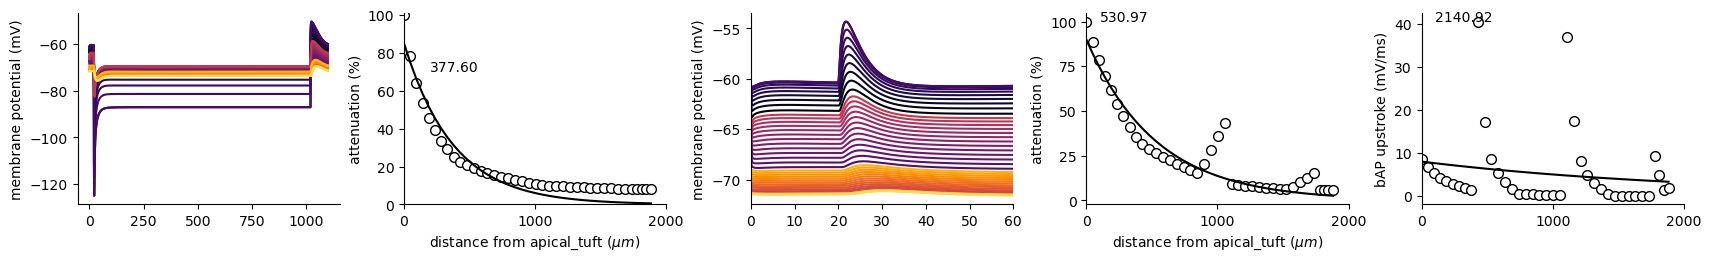

In [19]:
h.dt = 0.025  # explicit dt (chirp and action potential set their own)
model = get_l5pyr()
section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
ref_sect = 'apical_tuft'

fig = plot_attenuation(model=model, section_names=section_names, ref_sect=ref_sect, use_epsp=True, cols_dist=cols_dist)
fig.savefig(figpth / 'l5_attenuation_dend_soma.png', dpi=300)
fig.savefig(figpth / 'l5_attenuation_dend_soma.pdf', dpi=300)
plt.show()

## Supp. Fig. 2c — sag ratio and input resistance

Sag ratio and input resistance as a function of distance from the soma
(Beaulieu-Laroche et al. 2018).

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_bro

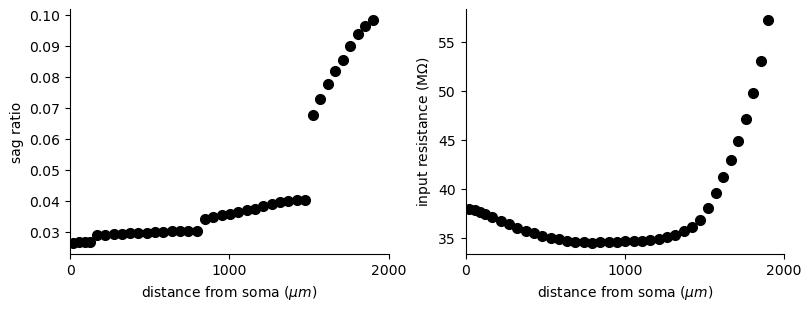

In [20]:
h.dt = 0.025  # explicit dt (chirp and action potential set their own)
l5pyr = get_l5pyr()

# Voltage sag as a function of distance
amp = -.5
sag_ratio = []
section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
for s, section in enumerate(section_names):
    for i, seg in enumerate(l5pyr._nrn_sections[section]):
        l5pyr = get_l5pyr()

        stim = h.IClamp(l5pyr._nrn_sections[section](seg.x))
        stim.delay = 20
        stim.dur = 150
        stim.amp = amp

        t = h.Vector().record(h._ref_t)
        soma_voltg = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_v)

        h.celsius = 37
        h.finitialize()
        h.continuerun(250 * ms)

        steady_idx = np.argmin(np.abs(t - 150))
        soma_v = soma_voltg.as_numpy()
        pk = np.min(soma_v)
        steady_state = soma_v[steady_idx]
        # Sag ratio - see Beaulieu-Laroche, 2018
        sag_ratio.append((pk - steady_state) / pk)

# input resistance as a function of distance
inp_res = []
for s, section in enumerate(section_names):
    for i, seg in enumerate(l5pyr._nrn_sections[section]):
        del l5pyr
        l5pyr = get_l5pyr()

        impedance = h.Impedance()
        h.celsius = 37
        h.finitialize()
        impedance.loc(seg.x, sec=l5pyr._nrn_sections[section])
        impedance.compute(0)
        inp_res.append(impedance.input(l5pyr._nrn_sections[section](seg.x)))

# distance from soma (separate loop: l5pyr is repeatedly deleted above)
distance = []
h.distance(sec=l5pyr._nrn_sections['soma'])
for section in section_names:
    for i, seg in enumerate(l5pyr._nrn_sections[section]):
        distance.append(h.distance(seg.x, sec=seg.sec))

fig, ax = plt.subplots(1, 2, figsize=(8, 3), constrained_layout=True)
ax[0].plot(distance, sag_ratio, 'o', color='k', markersize=7)
ax[0].set_ylabel('sag ratio')
ax[0].set_xlabel(r'distance from soma ($\mu m$)')
ax[1].plot(distance, inp_res, 'o', color='k', markersize=7)
ax[1].set_xlabel(r'distance from soma ($\mu m$)')
ax[1].set_ylabel(r'input resistance (M$\Omega$)')

for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.set_xlim([0, 2000])
    a.set_xticks([0, 1000, 2000])

fig.savefig(figpth / 'l5_sag_input_resistance.png', dpi=300)
fig.savefig(figpth / 'l5_sag_input_resistance.pdf', dpi=300)
fig.savefig(figpth / 'l5_sag_input_resistance.svg', dpi=300)
plt.show()

## Supp. Fig. 2f — single-cell dipolar currents

Dipole moment of a single, isolated L5 pyramidal cell (hnn-core
`duecker_ET_model(mesh_shape=(1, 1))` with connectivity cleared; dipole via the
standard `simulate_dipole` pipeline). Top row: somatic stimulation; bottom row:
apical-tuft stimulation.

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
No baseline correction applied.
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
No baseline correction applied.


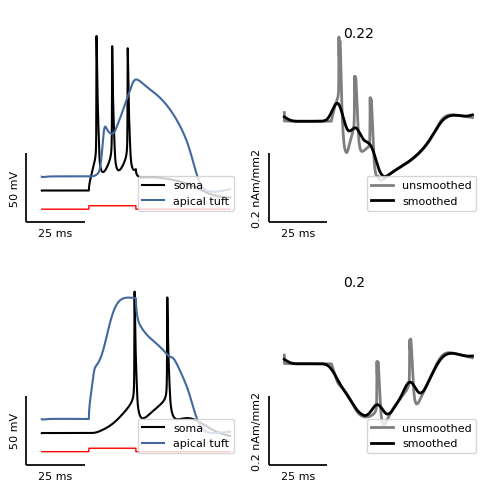

In [23]:
fig, axs = plt.subplots(2, 2, figsize=(5, 5), sharex=True)

gid = 3  # the single L5 pyramidal cell in the (1, 1) mesh

net, dpl, smooth_dpl = stim_dpl(duecker_ET_model(mesh_shape=(1, 1)), stim_cell='L5_pyramidal', ampl=3)
plot_dpl(net, dpl, smooth_dpl, axs[0, :], gid, cell_type='L5_pyramidal', dpl_ylim=(-0.3, 0.3), sb_dpl=0.2)

net, dpl, smooth_dpl = stim_dpl(duecker_ET_model(mesh_shape=(1, 1)), stim_cell='L5_pyramidal', stim_section='apical_tuft', ampl=1)
plot_dpl(net, dpl, smooth_dpl, axs[1, :], gid, cell_type='L5_pyramidal', dpl_ylim=(-0.3, 0.3), sb_dpl=0.2)


fig.tight_layout()
fig.savefig(figpth / 'l5_dipolar_currents.png', dpi=300, bbox_inches='tight')
fig.savefig(figpth / 'l5_dipolar_currents.pdf', dpi=300, bbox_inches='tight')
fig.savefig(figpth / 'l5_dipolar_currents.svg', dpi=300, bbox_inches='tight')